In [2]:
import sys

sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

data = get_runs_data(
    tag="karity",
    project="memorization",
    metrics=[
        "train/exact_match_embed_cond"
    ],
)
show_config_differences(data)

Found 3 runs with tag 'karity'


,cfg.dataset.npz_path,cfg.dataset_metadata.K
_run_id,,
95q06xa8,datasets/karity_K1_seed0.npz,1
huchenz0,datasets/karity_K3_seed0.npz,3
qafqpnny,datasets/karity_K2_seed0.npz,2


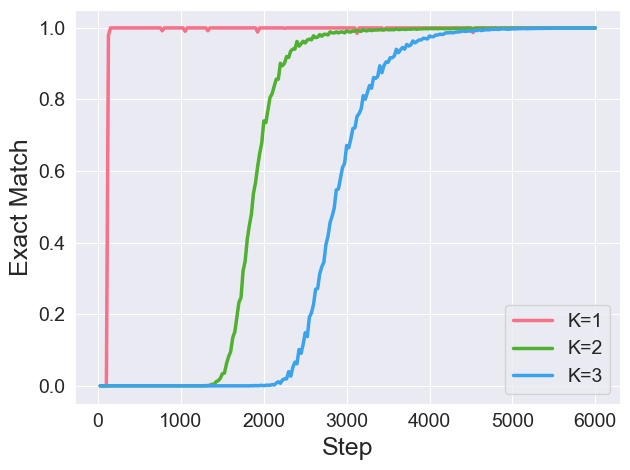

In [5]:
import numpy as np

metric_name = "train/exact_match_embed_cond"
k_col = "cfg.dataset_metadata.K"
step_col = "train/global_step"
max_step = 6000

filtered_data = data[data[step_col] <= max_step]
stats = filtered_data.groupby([k_col, step_col])[metric_name].agg(['mean', 'std']).reset_index()

k_values = sorted(stats[k_col].unique())
colors = sns.color_palette("husl", len(k_values))

for i, k in enumerate(k_values):
    k_data = stats[stats[k_col] == k]
    steps = k_data[step_col]
    mean = k_data['mean']
    std = k_data['std'].fillna(0)

    plt.plot(steps, mean, label=f"K={k}", color=colors[i], linewidth=2.5)
    plt.fill_between(steps, np.clip(mean - std, 0, 1), np.clip(mean + std, 0, 1), alpha=0.2, color=colors[i])

plt.xlabel('Step', fontsize=18)
plt.ylabel('Exact Match', fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()